In [2]:
!pip install pandas
!pip install mongo
!pip install matplotlib
!pip install seaborn

from pymongo import MongoClient
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
client = MongoClient('mongodb://localhost:27017')

db = client['Football_Data']

collection_Game_lineups = db['game_lineups']

documents = collection_Game_lineups.find()

Game_lineups_df = pd.DataFrame(list(documents)).drop('_id', axis=1)
Game_lineups_df

,game_lineups_id,game_id,club_id,type,number,player_id,player_name,team_captain,position
0,77b0f371923e0c8bdf050a1e269faaac,3606208,338,starting_lineup,89,419061,Vladyslav Supryaga,0,Centre-Forward
1,cb6eeedb9f728570615d37b6fe7facaf,3606208,338,starting_lineup,10,368611,Mykola Shaparenko,0,Central Midfield
2,8e63d5f47aac2bdb0e54f5481986e104,3606208,338,starting_lineup,5,124182,Sergiy Sydorchuk,1,Defensive Midfield
3,ea4a96d8be410f2d646cf095c4faae7f,3606208,338,starting_lineup,94,181118,Tomasz Kedziora,0,Right-Back
4,e6abe553801b09bc623c3deb96acba17,3606208,338,starting_lineup,16,404842,Vitaliy Mykolenko,0,Left-Back
...,...,...,...,...,...,...,...,...,...
119128,f4e6a6b2e3d24d12290c6ce4168e1bdb,4228114,46889,substitutes,3,1200869,Thomas Chambers,0,Left-Back
119129,7a78814a66c59c79e8d40c8669a67d3f,4228114,46889,substitutes,5,1203716,Mohammed-Idris Oshilaja,0,Defender
119130,09cc07767ce441b4de4a76c102fd17d5,4228114,46889,substitutes,13,1200870,Max Ovenden,0,Goalkeeper
119131,3c259f1849421af021aba3e84a4da8de,4228114,46889,substitutes,12,550816,Julien Anau,0,Attacking Midfield


In [12]:
#all'interno del database cosidero i dati seguenti: Game_id, Club_id, type, number, player_id, player_name
#team_captain e position per poter effettuare delle analisi.
Game_lineups_df = Game_lineups_df.drop('game_lineups_id', axis=1)
Game_lineups_df

,game_id,club_id,type,number,player_id,player_name,team_captain,position
0,3606208,338,starting_lineup,89,419061,Vladyslav Supryaga,0,Centre-Forward
1,3606208,338,starting_lineup,10,368611,Mykola Shaparenko,0,Central Midfield
2,3606208,338,starting_lineup,5,124182,Sergiy Sydorchuk,1,Defensive Midfield
3,3606208,338,starting_lineup,94,181118,Tomasz Kedziora,0,Right-Back
4,3606208,338,starting_lineup,16,404842,Vitaliy Mykolenko,0,Left-Back
...,...,...,...,...,...,...,...,...
119128,4228114,46889,substitutes,3,1200869,Thomas Chambers,0,Left-Back
119129,4228114,46889,substitutes,5,1203716,Mohammed-Idris Oshilaja,0,Defender
119130,4228114,46889,substitutes,13,1200870,Max Ovenden,0,Goalkeeper
119131,4228114,46889,substitutes,12,550816,Julien Anau,0,Attacking Midfield


In [24]:
club_df= pd.read_csv('clubs.csv')[['club_id','name']]

club_game_lineups_df = pd.merge(Game_lineups_df, club_df, how='left', on='club_id')
club_game_lineups_df = club_game_lineups_df[~club_game_lineups_df['name'].isna()]
club_game_lineups_df = club_game_lineups_df[~club_game_lineups_df['club_id'].isna()] #il club_id è un dato fondamentale per la mia analisi
club_game_lineups_df = club_game_lineups_df[~club_game_lineups_df['player_id'].isna()] #il club_id è un dato fondamentale per la mia analisi
club_game_lineups_df

,game_id,club_id,type,number,player_id,player_name,team_captain,position,name
0,3606208,338,starting_lineup,89,419061,Vladyslav Supryaga,0,Centre-Forward,Futbolniy Klub Dynamo Kyiv
1,3606208,338,starting_lineup,10,368611,Mykola Shaparenko,0,Central Midfield,Futbolniy Klub Dynamo Kyiv
2,3606208,338,starting_lineup,5,124182,Sergiy Sydorchuk,1,Defensive Midfield,Futbolniy Klub Dynamo Kyiv
3,3606208,338,starting_lineup,94,181118,Tomasz Kedziora,0,Right-Back,Futbolniy Klub Dynamo Kyiv
4,3606208,338,starting_lineup,16,404842,Vitaliy Mykolenko,0,Left-Back,Futbolniy Klub Dynamo Kyiv
...,...,...,...,...,...,...,...,...,...
118755,4227848,3060,substitutes,16,164729,Panagiotis Tsintotas,0,Goalkeeper,APS Atromitos Athinon
118756,4227848,3060,substitutes,6,456523,Eder González,0,Defensive Midfield,APS Atromitos Athinon
118757,4227848,3060,substitutes,27,726717,Konstantinos Pomonis,0,Left-Back,APS Atromitos Athinon
118758,4227848,3060,substitutes,20,533239,Antonis Trimmatis,0,Right Winger,APS Atromitos Athinon


In [44]:
#adesso andrò ad analizzare quali sono i giocatori che mette al fischio di inizio una squadra x.
#come squadra di esempio prenderò: 'Royal Sporting Club Anderlecht'

Royal_Sporting_Club_Anderlecht_gamelineups_df = club_game_lineups_df[club_game_lineups_df['name'] == 'Royal Sporting Club Anderlecht']
Royal_Sporting_Club_Anderlecht_gamelineups_df

,game_id,club_id,type,number,player_id,player_name,team_captain,position,name
13332,4093105,58,starting_lineup,7,423604,Francis Amuzu,0,Left Winger,Royal Sporting Club Anderlecht
13333,4093105,58,starting_lineup,18,360140,Majeed Ashimeru,0,Central Midfield,Royal Sporting Club Anderlecht
13334,4093105,58,starting_lineup,36,342389,Anders Dreyer,0,Right Winger,Royal Sporting Club Anderlecht
13335,4093105,58,starting_lineup,14,43250,Jan Vertonghen,1,Centre-Back,Royal Sporting Club Anderlecht
13336,4093105,58,starting_lineup,1,127188,Maxime Dupé,0,Goalkeeper,Royal Sporting Club Anderlecht
...,...,...,...,...,...,...,...,...,...
36799,4098971,58,substitutes,36,342389,Anders Dreyer,0,Right Winger,Royal Sporting Club Anderlecht
36800,4098971,58,substitutes,22,502247,Louis Patris,0,Right-Back,Royal Sporting Club Anderlecht
36801,4098971,58,substitutes,21,355501,Amadou Diawara,0,Defensive Midfield,Royal Sporting Club Anderlecht
36802,4098971,58,substitutes,61,581106,Kristian Arnstad,0,Central Midfield,Royal Sporting Club Anderlecht


In [53]:
#controllo quanti valori ha type
types = Royal_Sporting_Club_Anderlecht_gamelineups_df[['type']]
types = types.drop_duplicates()
types

,type
13332,starting_lineup
13343,substitutes


In [45]:
Royal_Sporting_Club_Anderlecht_startinglineups_df = Royal_Sporting_Club_Anderlecht_gamelineups_df[Royal_Sporting_Club_Anderlecht_gamelineups_df['type'] == 'starting_lineup']
Royal_Sporting_Club_Anderlecht_startinglineups_df

,game_id,club_id,type,number,player_id,player_name,team_captain,position,name
13332,4093105,58,starting_lineup,7,423604,Francis Amuzu,0,Left Winger,Royal Sporting Club Anderlecht
13333,4093105,58,starting_lineup,18,360140,Majeed Ashimeru,0,Central Midfield,Royal Sporting Club Anderlecht
13334,4093105,58,starting_lineup,36,342389,Anders Dreyer,0,Right Winger,Royal Sporting Club Anderlecht
13335,4093105,58,starting_lineup,14,43250,Jan Vertonghen,1,Centre-Back,Royal Sporting Club Anderlecht
13336,4093105,58,starting_lineup,1,127188,Maxime Dupé,0,Goalkeeper,Royal Sporting Club Anderlecht
...,...,...,...,...,...,...,...,...,...
36792,4098971,58,starting_lineup,12,283196,Kasper Dolberg,0,Centre-Forward,Royal Sporting Club Anderlecht
36793,4098971,58,starting_lineup,15,170646,Ludwig Augustinsson,0,Left-Back,Royal Sporting Club Anderlecht
36794,4098971,58,starting_lineup,56,548193,Zeno Debast,0,Centre-Back,Royal Sporting Club Anderlecht
36795,4098971,58,starting_lineup,54,454336,Killian Sardella,0,Right-Back,Royal Sporting Club Anderlecht


In [94]:
#adesso vado a rimuovere i giocatori che attualmente sono nel 'rsc-Anderlecht'
player_df= pd.read_csv('players.csv')[['player_id', 'name', 'current_club_id']]
player_clubs_df = player_df[['current_club_id']].copy()
player_clubs_df.rename(columns={'current_club_id': 'club_id'}, inplace=True)

rsc_anderlecht_startinglineups_df = pd.merge(Royal_Sporting_Club_Anderlecht_startinglineups_df, player_clubs_df, how='left', on='club_id')
rsc_anderlecht_startinglineups_df = rsc_anderlecht_startinglineups_df.drop_duplicates()
rsc_anderlecht_startinglineups_df

,game_id,club_id,type,number,player_id,player_name,team_captain,position,name
0,4093105,58,starting_lineup,7,423604,Francis Amuzu,0,Left Winger,Royal Sporting Club Anderlecht
75,4093105,58,starting_lineup,18,360140,Majeed Ashimeru,0,Central Midfield,Royal Sporting Club Anderlecht
150,4093105,58,starting_lineup,36,342389,Anders Dreyer,0,Right Winger,Royal Sporting Club Anderlecht
225,4093105,58,starting_lineup,14,43250,Jan Vertonghen,1,Centre-Back,Royal Sporting Club Anderlecht
300,4093105,58,starting_lineup,1,127188,Maxime Dupé,0,Goalkeeper,Royal Sporting Club Anderlecht
...,...,...,...,...,...,...,...,...,...
12000,4098971,58,starting_lineup,12,283196,Kasper Dolberg,0,Centre-Forward,Royal Sporting Club Anderlecht
12075,4098971,58,starting_lineup,15,170646,Ludwig Augustinsson,0,Left-Back,Royal Sporting Club Anderlecht
12150,4098971,58,starting_lineup,56,548193,Zeno Debast,0,Centre-Back,Royal Sporting Club Anderlecht
12225,4098971,58,starting_lineup,54,454336,Killian Sardella,0,Right-Back,Royal Sporting Club Anderlecht


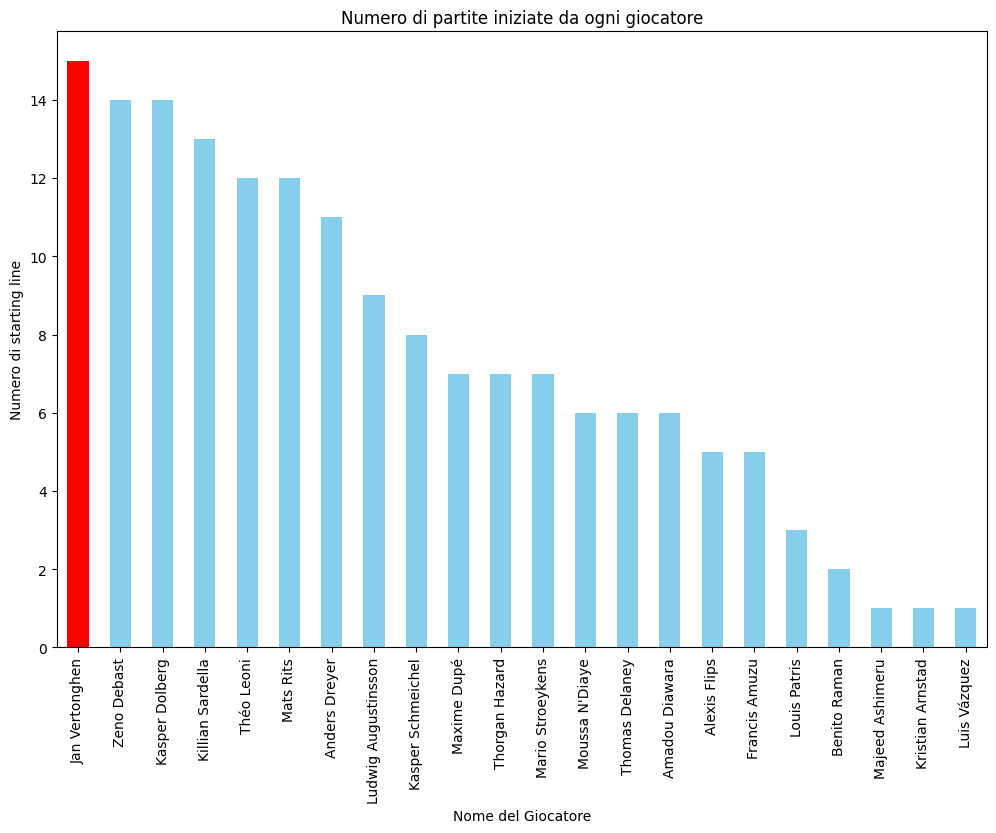

In [95]:
#ora voglio creare un grafico per vedere quante volte ogni giocatore del rsc-anderlecht ha fatto parte della starting lineups,
#evidenziando di rosso il capitano del team.

player_start_counts = rsc_anderlecht_startinglineups_df['player_name'].value_counts()
is_captain = rsc_anderlecht_startinglineups_df.groupby('player_name')['team_captain'].max()

colors = ['red' if is_captain[player] == 1 else 'skyblue' for player in player_start_counts.index]

plt.figure(figsize=(12, 8))
player_start_counts.plot(kind='bar', color=colors)
plt.xlabel('Nome del Giocatore')
plt.ylabel('Numero di starting line')
plt.title('Numero di partite iniziate da ogni giocatore')
plt.xticks(rotation=90)
plt.show()

In [96]:
#ora invece andrò a vedere quale sia il giocatore che entra più volte come sostituto.
#prima vado a filtrare per ottenere tutti i giocatori con type substitute

Royal_Sporting_Club_Anderlecht_substitute_df = Royal_Sporting_Club_Anderlecht_gamelineups_df[Royal_Sporting_Club_Anderlecht_gamelineups_df['type'] == 'substitutes']
Royal_Sporting_Club_Anderlecht_substitute_df

,game_id,club_id,type,number,player_id,player_name,team_captain,position,name
13343,4093105,58,substitutes,55,486051,Marco Kana,0,Defensive Midfield,Royal Sporting Club Anderlecht
13344,4093105,58,substitutes,29,588866,Mario Stroeykens,0,Second Striker,Royal Sporting Club Anderlecht
13345,4093105,58,substitutes,9,112930,Benito Raman,0,Centre-Forward,Royal Sporting Club Anderlecht
13346,4093105,58,substitutes,54,454336,Killian Sardella,0,Right-Back,Royal Sporting Club Anderlecht
13347,4093105,58,substitutes,26,154351,Colin Coosemans,0,Goalkeeper,Royal Sporting Club Anderlecht
...,...,...,...,...,...,...,...,...,...
36799,4098971,58,substitutes,36,342389,Anders Dreyer,0,Right Winger,Royal Sporting Club Anderlecht
36800,4098971,58,substitutes,22,502247,Louis Patris,0,Right-Back,Royal Sporting Club Anderlecht
36801,4098971,58,substitutes,21,355501,Amadou Diawara,0,Defensive Midfield,Royal Sporting Club Anderlecht
36802,4098971,58,substitutes,61,581106,Kristian Arnstad,0,Central Midfield,Royal Sporting Club Anderlecht


In [97]:
rsc_anderlecht_substitute_df = pd.merge(Royal_Sporting_Club_Anderlecht_substitute_df, player_clubs_df, how='left', on='club_id')
rsc_anderlecht_substitute_df = rsc_anderlecht_substitute_df.drop_duplicates()
rsc_anderlecht_substitute_df

,game_id,club_id,type,number,player_id,player_name,team_captain,position,name
0,4093105,58,substitutes,55,486051,Marco Kana,0,Defensive Midfield,Royal Sporting Club Anderlecht
75,4093105,58,substitutes,29,588866,Mario Stroeykens,0,Second Striker,Royal Sporting Club Anderlecht
150,4093105,58,substitutes,9,112930,Benito Raman,0,Centre-Forward,Royal Sporting Club Anderlecht
225,4093105,58,substitutes,54,454336,Killian Sardella,0,Right-Back,Royal Sporting Club Anderlecht
300,4093105,58,substitutes,26,154351,Colin Coosemans,0,Goalkeeper,Royal Sporting Club Anderlecht
...,...,...,...,...,...,...,...,...,...
7500,4098971,58,substitutes,36,342389,Anders Dreyer,0,Right Winger,Royal Sporting Club Anderlecht
7575,4098971,58,substitutes,22,502247,Louis Patris,0,Right-Back,Royal Sporting Club Anderlecht
7650,4098971,58,substitutes,21,355501,Amadou Diawara,0,Defensive Midfield,Royal Sporting Club Anderlecht
7725,4098971,58,substitutes,61,581106,Kristian Arnstad,0,Central Midfield,Royal Sporting Club Anderlecht


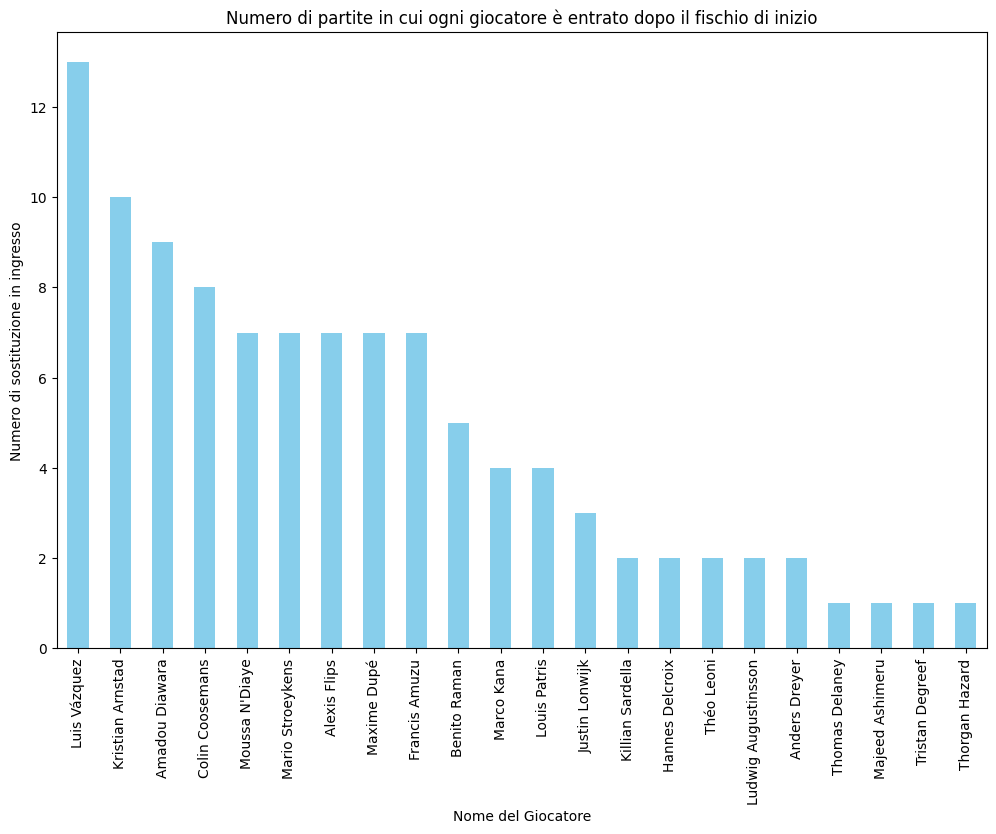

In [98]:
#ora voglio creare un grafico per vedere quante volte ogni giocatore del rsc-anderlecht è stato fatto entrare dopo
#il fischio di inizio

player_substitute_counts = rsc_anderlecht_substitute_df['player_name'].value_counts()

plt.figure(figsize=(12, 8))
player_substitute_counts.plot(kind='bar', color='skyblue')
plt.xlabel('Nome del Giocatore')
plt.ylabel('Numero di sostituzione in ingresso')
plt.title('Numero di partite in cui ogni giocatore è entrato dopo il fischio di inizio')
plt.xticks(rotation=90)
plt.show()

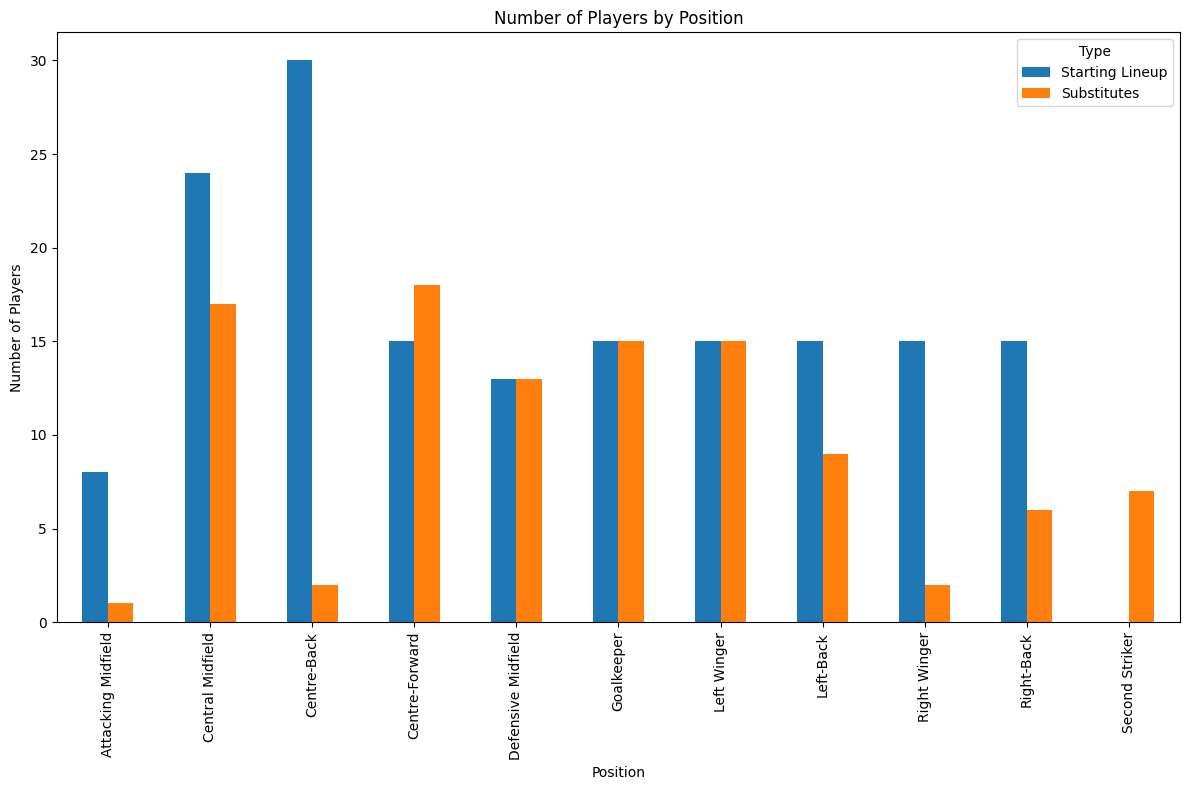

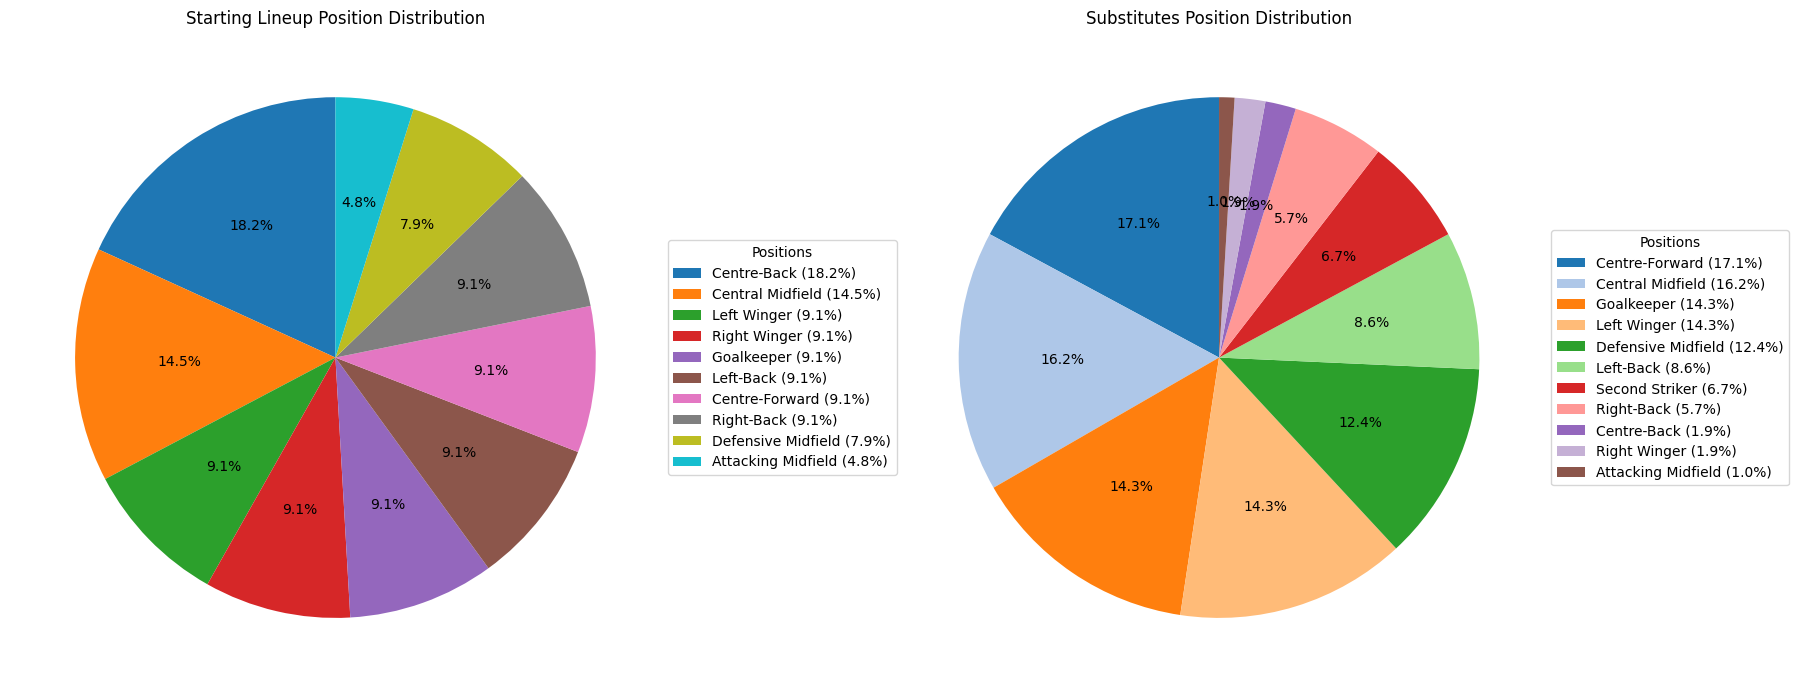

In [99]:
#adesso vado ad analizzare le posizioni dei giocatori in quali percentuali questi partano in campo al fischio di inizio,
#e quali invece vengano sostituiti in ingresso dopo il fischio di inizio (considenrando sempre la medesima squadra di esempio).

start_position_counts = rsc_anderlecht_startinglineups_df['position'].value_counts()
sub_position_counts = rsc_anderlecht_substitute_df['position'].value_counts()

position_counts = pd.DataFrame({
    'Starting Lineup': start_position_counts,
    'Substitutes': sub_position_counts
}).fillna(0)

fig_bar, ax1 = plt.subplots(figsize=(12, 8))

position_counts.plot(kind='bar', ax=ax1)
ax1.set_xlabel('Position')
ax1.set_ylabel('Number of Players')
ax1.set_title('Number of Players by Position')
ax1.legend(title='Type')

plt.tight_layout()
plt.show()

fig_pie, (ax2, ax3) = plt.subplots(1, 2, figsize=(18, 8))

def get_labels_with_percentages(counts):
    total = counts.sum()
    return [f"{position} ({count/total:.1%})" for position, count in counts.items()]

colors1 = plt.cm.tab10.colors  # Prima palette di colori
colors2 = plt.cm.tab20.colors  # Seconda palette di colori

wedges1, texts1, autotexts1 = ax2.pie(start_position_counts, autopct='%1.1f%%', startangle=90, colors=colors1)
ax2.set_title('Starting Lineup Position Distribution')
labels1 = get_labels_with_percentages(start_position_counts)
ax2.legend(wedges1, labels1, title="Positions", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

wedges2, texts2, autotexts2 = ax3.pie(sub_position_counts, autopct='%1.1f%%', startangle=90, colors=colors2)
ax3.set_title('Substitutes Position Distribution')
labels2 = get_labels_with_percentages(sub_position_counts)
ax3.legend(wedges2, labels2, title="Positions", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

plt.tight_layout()
plt.show()

#come si può notare il ruolo con più giocatori in campo al fischio di inizio è il 'center-back', mentre il ruolo con meno giocatori è
#'attacking-midfield', non ho menzionato il 'second stricker' perché per definizione è un ruolo di supporto che non si mette mai in campo
#al fischio di inizio.

In [100]:
#adesso andrò a mergiare con il database game_events per poter fare un analisi più approfondita del motivo di sostituzioni
#dei giocatori

collection_game_events = db['game_events']

documents = collection_game_events.find()

game_events_df = pd.DataFrame(list(documents)).drop('_id', axis=1)

In [101]:
game_events_filtered_df = game_events_df[['game_id', 'type', 'player_id', 'description', 'player_in_id']]
game_events_filtered_df = game_events_filtered_df[game_events_filtered_df['type'] == 'Substitutions']
game_events_substitution_df = game_events_filtered_df[~(game_events_filtered_df['description'] == ', Not reported')].copy()
game_events_substitution_df.rename(columns={'player_id': 'player_out_id'}, inplace=True)
game_events_substitution_df.rename(columns={'player_in_id': 'player_id'}, inplace=True)
game_events_substitution_df

,game_id,type,player_out_id,description,player_id
81,2221746,Substitutions,21318,", Tactical",125231.0
85,2221746,Substitutions,79268,", Tactical",43492.0
86,2221746,Substitutions,99003,", Tactical",32485.0
88,2221746,Substitutions,139942,", Tactical",94637.0
92,2221747,Substitutions,2125,", Tactical",43984.0
...,...,...,...,...,...
666550,4228114,Substitutions,814815,", Tactical",550816.0
666551,4228114,Substitutions,839808,", Injury",1203716.0
666553,4228114,Substitutions,874064,", Tactical",965607.0
666555,4228114,Substitutions,922572,", Tactical",1200869.0


In [110]:
substitution_rsc_Anderlecht_df = pd.merge(rsc_anderlecht_substitute_df, game_events_substitution_df, how='left', on=['player_id', 'game_id'])

substitution_rsc_Anderlecht_df = substitution_rsc_Anderlecht_df[~(substitution_rsc_Anderlecht_df['description'].isna())]
substitution_rsc_Anderlecht_df = substitution_rsc_Anderlecht_df.drop('team_captain', axis=1)
substitution_rsc_Anderlecht_df = substitution_rsc_Anderlecht_df.drop('type_y', axis=1)
substitution_rsc_Anderlecht_df = substitution_rsc_Anderlecht_df.drop('type_x', axis=1)
substitution_rsc_Anderlecht_df = substitution_rsc_Anderlecht_df.drop('number', axis=1)

player_name_df = player_df[['player_id', 'name']].copy()
player_name_df.rename(columns={'player_id': 'player_out_id'}, inplace=True)
player_name_df.rename(columns={'name': 'player_out_name'}, inplace=True)

substitution_rsc_Anderlecht_df = pd.merge(substitution_rsc_Anderlecht_df, player_name_df, how='left', on=['player_out_id'])

rsc_Anderlecht_df = Royal_Sporting_Club_Anderlecht_gamelineups_df[['player_name', 'position']].copy()
rsc_Anderlecht_df.rename(columns={'player_name': 'player_out_name'}, inplace=True)

substitution_rsc_Anderlecht_df = pd.merge(substitution_rsc_Anderlecht_df, rsc_Anderlecht_df, how='left', on='player_out_name')
substitution_rsc_Anderlecht_df = substitution_rsc_Anderlecht_df.drop_duplicates()

substitution_rsc_Anderlecht_df.rename(columns={'position_x': 'position_player_in'},inplace=True)
substitution_rsc_Anderlecht_df.rename(columns={'position_y': 'position_player_out'}, inplace=True)
substitution_rsc_Anderlecht_df = substitution_rsc_Anderlecht_df.drop('club_id', axis=1)

substitution_rsc_Anderlecht_df

,game_id,player_id,player_name,position_player_in,name,player_out_id,description,player_out_name,position_player_out
0,4093105,588866,Mario Stroeykens,Second Striker,Royal Sporting Club Anderlecht,355501.0,", Tactical",Amadou Diawara,Defensive Midfield
15,4093105,112930,Benito Raman,Centre-Forward,Royal Sporting Club Anderlecht,360140.0,", Tactical",Majeed Ashimeru,Central Midfield
17,4093105,454336,Killian Sardella,Right-Back,Royal Sporting Club Anderlecht,502247.0,", Tactical",Louis Patris,Right-Back
24,4093105,418071,Théo Leoni,Central Midfield,Royal Sporting Club Anderlecht,581106.0,", Tactical",Kristian Arnstad,Attacking Midfield
25,4093105,418071,Théo Leoni,Central Midfield,Royal Sporting Club Anderlecht,581106.0,", Tactical",Kristian Arnstad,Central Midfield
...,...,...,...,...,...,...,...,...,...
770,4098971,395242,Alexis Flips,Left Winger,Royal Sporting Club Anderlecht,102226.0,", Tactical",Thorgan Hazard,Left Winger
773,4098971,395242,Alexis Flips,Left Winger,Royal Sporting Club Anderlecht,102226.0,", Tactical",Thorgan Hazard,Right Winger
778,4098971,342389,Anders Dreyer,Right Winger,Royal Sporting Club Anderlecht,423604.0,", Injury",Francis Amuzu,Left Winger
790,4098971,355501,Amadou Diawara,Defensive Midfield,Royal Sporting Club Anderlecht,91849.0,", Injury",Thomas Delaney,Defensive Midfield


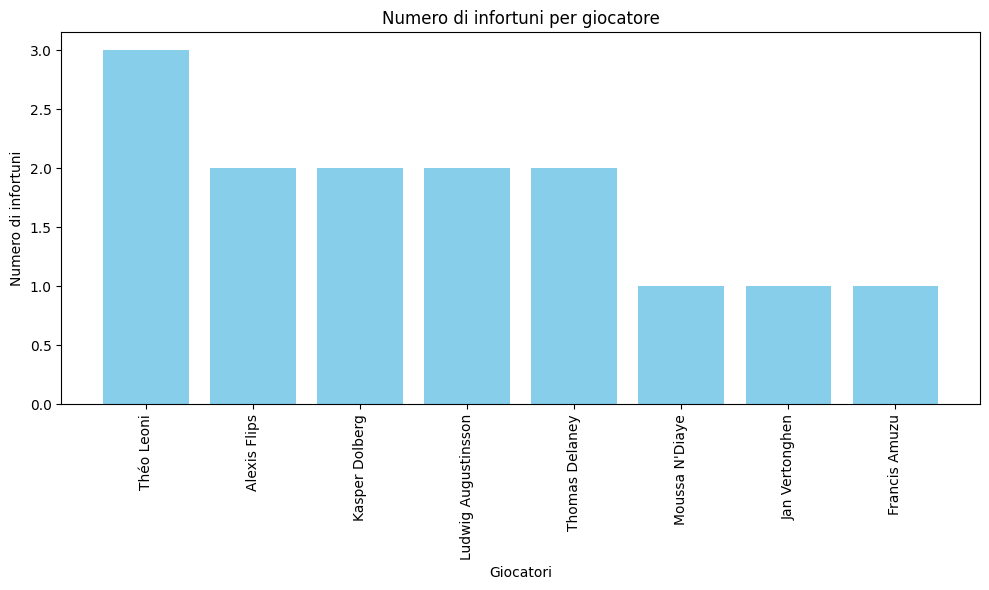

In [129]:
#inizio analizzando un sotto gruppo dell'insieme precedente riguandante i giocatori che si infortuniano di più.
#ho analizzato i giocatori che si infortunano di più della squadra presa ad esempio ottenendo questi risultato

game_injuries_df = substitution_rsc_Anderlecht_df[substitution_rsc_Anderlecht_df['description'] == ', Injury']
player_injuries_counts = game_injuries_df['player_out_name'].value_counts()

player_injuries_counts = player_injuries_counts.sort_values(ascending=False)

players = player_injuries_counts.index
counts = player_injuries_counts.values

plt.figure(figsize=(10, 6))
plt.bar(players, counts, color='skyblue')
plt.xlabel('Giocatori')
plt.ylabel('Numero di infortuni')
plt.title('Numero di infortuni per giocatore')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

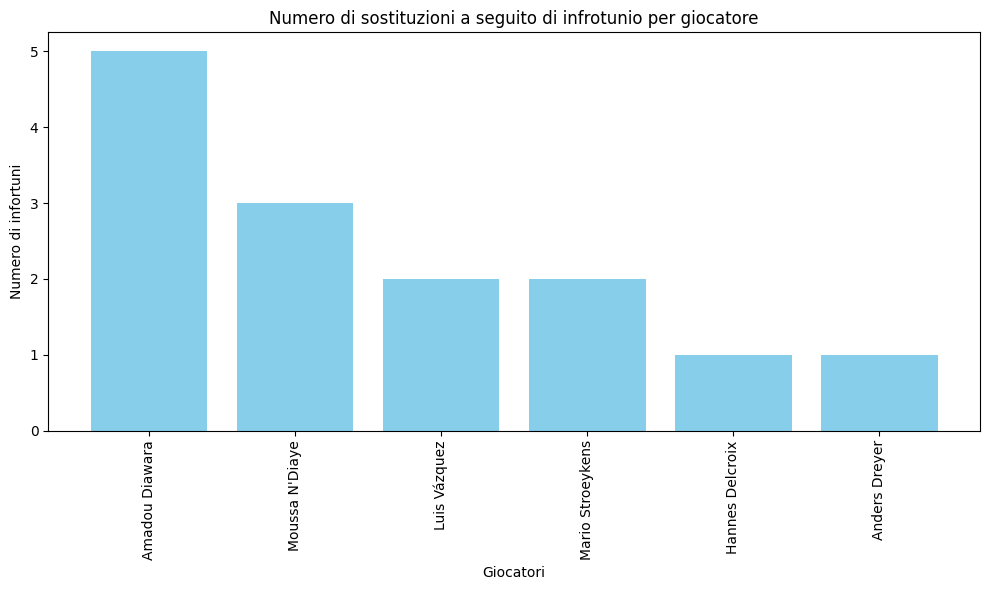

In [130]:
#ora invece analizzo i giocatori che entrano più spesso a seguito di un infortunio di un compagno

player_in_counts = game_injuries_df['player_name'].value_counts()

player_in_counts = player_in_counts.sort_values(ascending=False)

players = player_in_counts.index
counts = player_in_counts.values

plt.figure(figsize=(10, 6))
plt.bar(players, counts, color='skyblue')
plt.xlabel('Giocatori')
plt.ylabel('Numero di infortuni')
plt.title('Numero di sostituzioni a seguito di infrotunio per giocatore')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

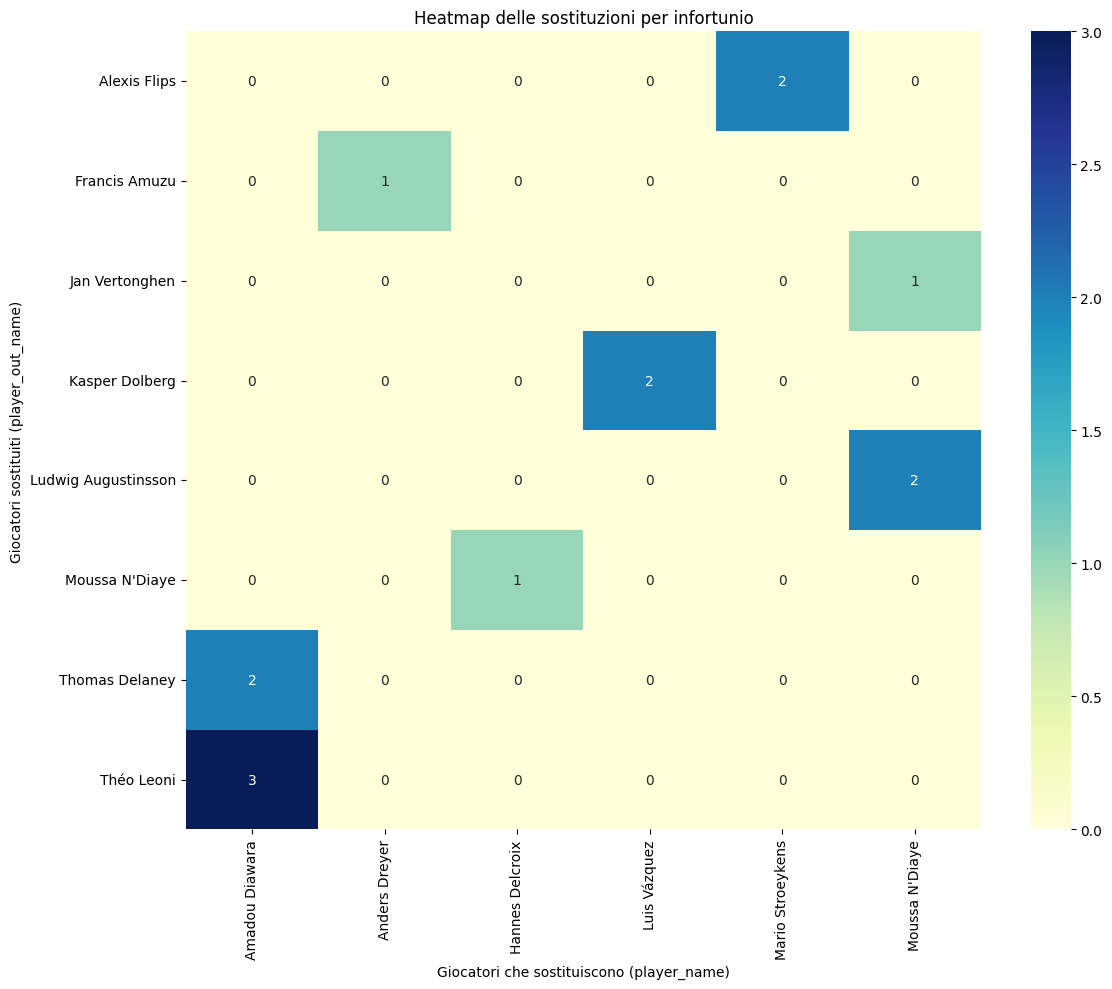

In [131]:
#ora utilizzando una heatmap vado a contare le occorrenze di ogni combinazione giocatore in/out

substitutes_after_injury = game_injuries_df.dropna(subset=['player_name'])

pivot_table = pd.pivot_table(substitutes_after_injury, 
                             index='player_out_name', 
                             columns='player_name', 
                             values='game_id', 
                             aggfunc='count', 
                             fill_value=0)

plt.figure(figsize=(12, 10))
sns.heatmap(pivot_table, cmap='YlGnBu', annot=True, fmt='g', cbar=True)
plt.title('Heatmap delle sostituzioni per infortunio')
plt.xlabel('Giocatori che sostituiscono (player_name)')
plt.ylabel('Giocatori sostituiti (player_out_name)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

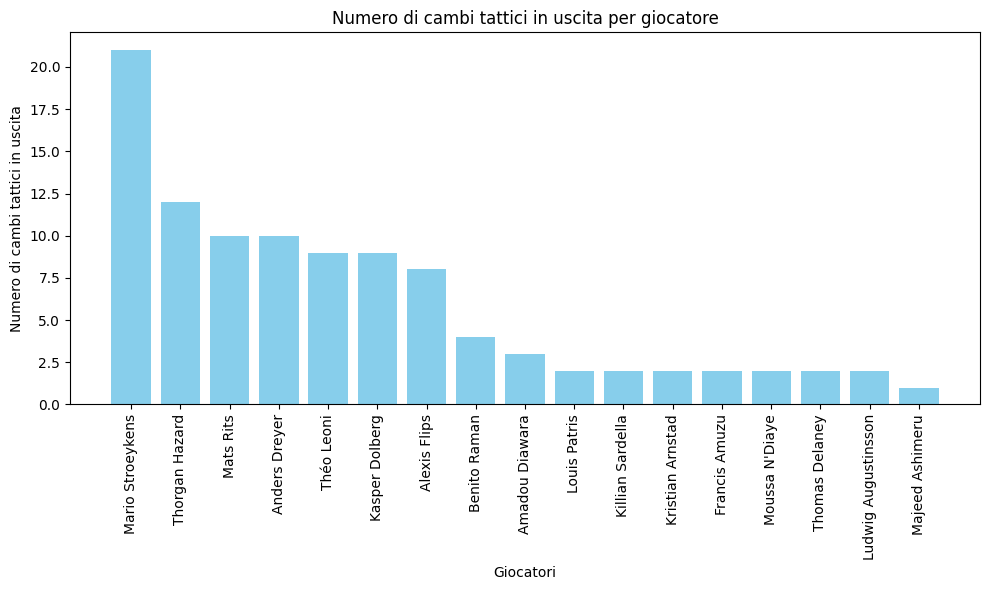

In [132]:
#ora analizzo un altro sotto gruppo dell'insieme precedente riguandante i giocatori che vengono sostituiti per motivi tattici.
#ho analizzato i giocatori che vengono sostituiti di più della squadra presa ad esempio ottenendo questi risultato

game_tactical_df = substitution_rsc_Anderlecht_df[substitution_rsc_Anderlecht_df['description'] == ', Tactical']
player_tactical_counts = game_tactical_df['player_out_name'].value_counts()

player_tactical_counts = player_tactical_counts.sort_values(ascending=False)

players = player_tactical_counts.index
counts = player_tactical_counts.values

plt.figure(figsize=(10, 6))
plt.bar(players, counts, color='skyblue')
plt.xlabel('Giocatori')
plt.ylabel('Numero di cambi tattici in uscita')
plt.title('Numero di cambi tattici in uscita per giocatore')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

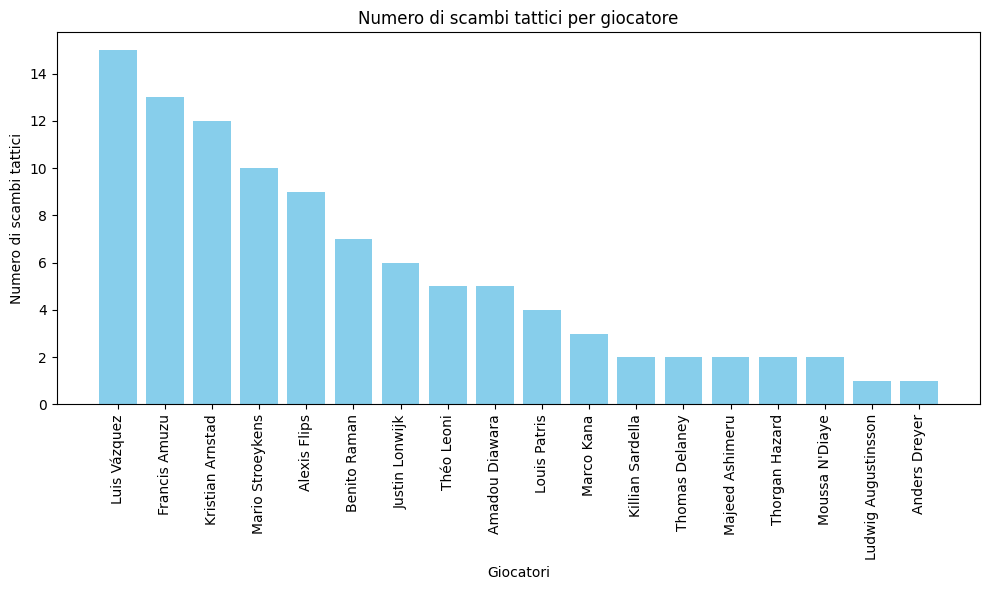

In [134]:
#ora invece analizzo i giocatori che entrano più spesso per motivi tattici

player_in_counts = game_tactical_df['player_name'].value_counts()

player_in_counts = player_in_counts.sort_values(ascending=False)

players = player_in_counts.index
counts = player_in_counts.values

plt.figure(figsize=(10, 6))
plt.bar(players, counts, color='skyblue')
plt.xlabel('Giocatori')
plt.ylabel('Numero di scambi tattici')
plt.title('Numero di scambi tattici per giocatore')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

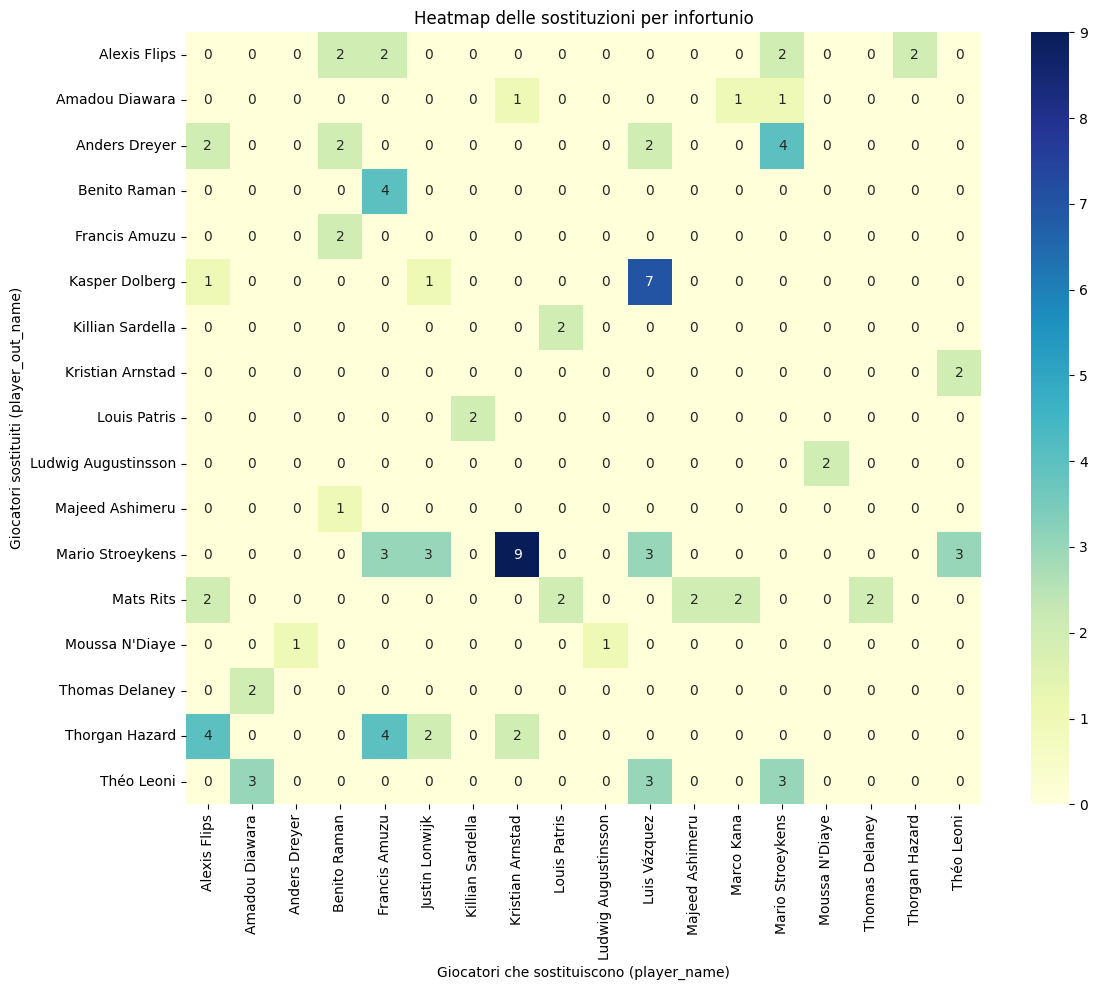

In [135]:
#ora utilizzando una heatmap vado a contare le occorrenze di ogni combinazione giocatore in/out

tactical_substitutes = game_tactical_df.dropna(subset=['player_name'])

pivot_table = pd.pivot_table(tactical_substitutes, 
                             index='player_out_name', 
                             columns='player_name', 
                             values='game_id', 
                             aggfunc='count', 
                             fill_value=0)

plt.figure(figsize=(12, 10))
sns.heatmap(pivot_table, cmap='YlGnBu', annot=True, fmt='g', cbar=True)
plt.title('Heatmap delle sostituzioni per infortunio')
plt.xlabel('Giocatori che sostituiscono (player_name)')
plt.ylabel('Giocatori sostituiti (player_out_name)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()